In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA_PATH = "/Users/alfadhul/Downloads/03_Machine_Learning/UTKFace"


In [2]:
files = os.listdir(DATA_PATH)
print(len(files))
print(files[:5])

23708
['9_1_2_20161219204347420.jpg.chip.jpg', '36_0_1_20170117163203851.jpg.chip.jpg', '86_1_0_20170120225751953.jpg.chip.jpg', '26_1_0_20170116171048641.jpg.chip.jpg', '1_1_2_20161219154612988.jpg.chip.jpg']


In [3]:
IMG_SIZE = 48
X = []
y = []
for f in files:
    if not f.endswith(".jpg"):
        continue
    age = int(f.split("_")[0])
    img = Image.open(os.path.join(DATA_PATH, f)).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    X.append(np.array(img))
    y.append(age)

X = np.array(X, dtype="uint8")
y = np.array(y, dtype="float32")
print(X.shape, y.shape, y.min(), y.max())

(23708, 48, 48, 3) (23708,) 1.0 116.0


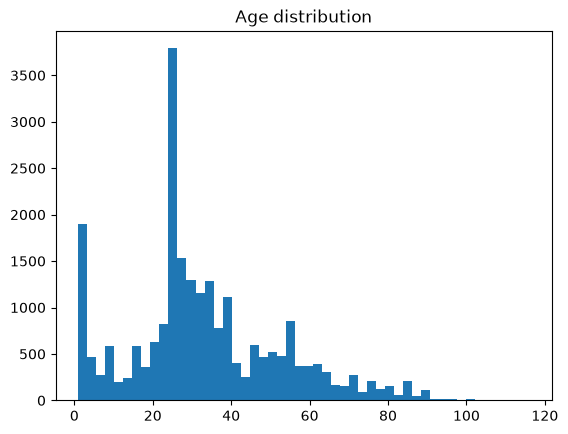

In [4]:
plt.hist(y, bins=50)
plt.title("Age distribution")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42)

baseline_mae = np.mean(np.abs(y_test - y_train.mean()))
print("Baseline MAE (always predict the mean age):", baseline_mae)

Baseline MAE (always predict the mean age): 15.412264


In [10]:
from keras import Sequential
from keras.layers import (
    Input, Rescaling, Conv2D, MaxPooling2D,
    Flatten, Dense
)

model = Sequential([
    Input(shape=(48, 48, 3)),
    Rescaling(1./255),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(2,2),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mae",
    metrics=["mae"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 46, 46, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 838,849 (3.20 MB)

 Trainable params: 838,849 (3.20 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
from keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_mae",
    patience=3,
    mode="min",
    restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - loss: 13.8047 - mae: 13.8047 - val_loss: 13.4317 - val_mae: 13.4317
Epoch 2/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - loss: 10.6291 - mae: 10.6291 - val_loss: 9.8777 - val_mae: 9.8777
Epoch 3/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - loss: 9.3772 - mae: 9.3772 - val_loss: 9.2956 - val_mae: 9.2956
Epoch 4/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - loss: 8.6425 - mae: 8.6425 - val_loss: 8.3470 - val_mae: 8.3470
Epoch 5/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - loss: 8.0826 - mae: 8.0826 - val_loss: 7.9994 - val_mae: 7.9994
Epoch 6/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - loss: 7.7017 - mae: 7.7017 - val_loss: 7.9442 - val_mae: 7.9442
Epoch 7/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - loss: 7.3998 - mae: 7.3998 - val_loss: 8.8858 - val_mae: 8.8858
Epoch 8/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - loss: 7.2028 - mae: 7.2028 - val_loss: 7.3507 - val_mae: 7.3507
Epoch 9/30
475/475 ━━━━━━━━━━━━━━━

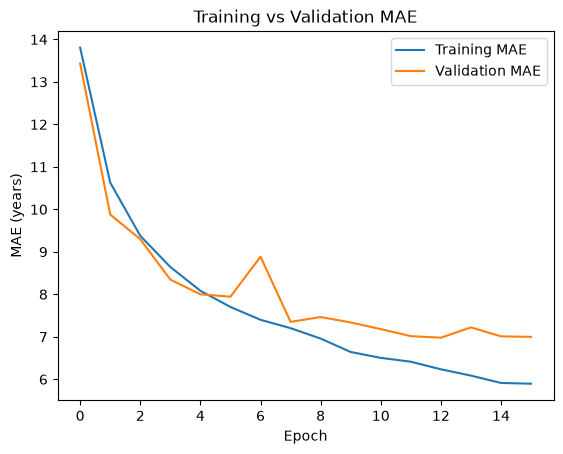

In [12]:
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE (years)")
plt.title("Training vs Validation MAE")
plt.legend()
plt.show()

In [13]:
test_loss, test_mae = model.evaluate(X_test, y_test)

print("Test MAE:", test_mae)
print("Baseline MAE:", baseline_mae)

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 7.0149 - mae: 7.0149
Test MAE: 7.014892578125
Baseline MAE: 15.412264


In [14]:
y_pred=model.predict(X_test).flatten()

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


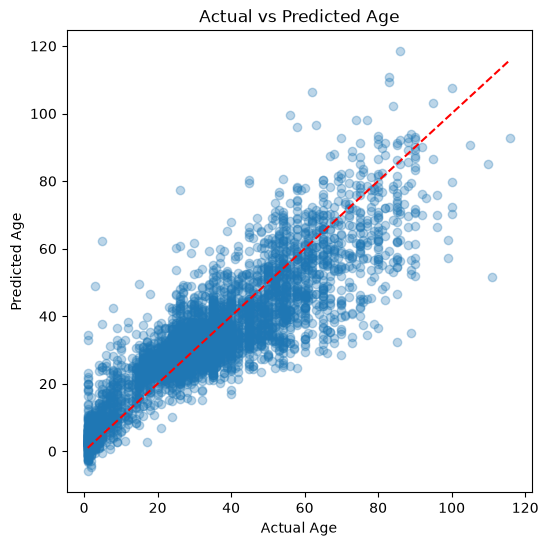

In [15]:
plt.figure(figsize=(6, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Age")
plt.ylabel("Predicted Age")
plt.title("Actual vs Predicted Age")
plt.show()

In [16]:
model.save("utkface_age_model.keras")